# devbrain E7.0-E10.0 - normalization, PCA, UMAP, Harmony

Input: `data/devbrain_E7-E10.h5ad` (68,177 called cells x 24,191 genes, raw UMI counts,
19 samples from PRJNA637987 / La Manno et al. 2021).

Figures are written per analysis under `output_fig/01_qc`, `02_pca_hvg`,
`03_umap_unintegrated`, `04_harmony_chip`, `05_hedgehog`.

In [1]:
import glob
import os

import h5py
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, dpi_save=200, frameon=False, figsize=(5, 5))

from matplotlib.colors import LinearSegmentedColormap

# Shared plotting constants. viridis (scanpy's default) puts its *darkest* end at
# zero, so on 68k mostly-zero cells the non-expressing majority dominates the
# picture. Sparse expression reads better as one hue light->dark over a flat grey
# background of non-expressing cells.
EXPR_CMAP = LinearSegmentedColormap.from_list(
    "expr", ["#FCC9B4", "#FB8A6A", "#E32F27", "#99000D"]
)
BG_GREY = "#DDDDDD"

In [2]:
base = "/project/imoskowitz/yubin/Trajectory_inference/"
data = base + "data/devbrain_E7-E10.h5ad"
output_fig = base + "output_fig/"

# One directory per analysis so the figures stay navigable. scanpy writes to
# sc.settings.figdir, so each section re-points it before plotting.
fig_qc      = output_fig + "01_qc/"
fig_pca     = output_fig + "02_pca_hvg/"
fig_umap    = output_fig + "03_umap_unintegrated/"
fig_harmony = output_fig + "04_harmony_chip/"
fig_genes   = output_fig + "05_hedgehog/"
for d in (fig_qc, fig_pca, fig_umap, fig_harmony, fig_genes):
    os.makedirs(d, exist_ok=True)
sc.settings.figdir = output_fig

In [5]:
adata = sc.read("/project/imoskowitz/yubin/Trajectory_inference/data/devbrain_E7-E10_processed.h5ad")
adata

AnnData object with n_obs × n_vars = 68166 × 21743
    obs: 'barcode', 'sample', 'run', 'age', 'tissue', 'total_counts', 'n_genes', 'is_cell', 'age_num', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'leiden'
    var: 'gene_ids', 'gene_symbol', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'age_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'source', 'tissue_colors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## Repair the missing gene symbols

`combine_h5ad.py` concatenated the per-sample matrices with `merge="first"`, which copies the
whole `gene_symbol` column from the *first* sample only. Genes that sample never detected were
reindexed to `NaN` - 5,334 of 24,191 rows. The symbols still exist in the other per-sample files
(each one carries the `GN` tag for the genes it saw), so rebuild the full Ensembl -> symbol map
from the union of all 19 files and cache it next to the metadata.

In [4]:
sym_csv = base + "data/metadata/gene_symbols.csv"

if not os.path.exists(sym_csv):
    mapping = {}
    for f in sorted(glob.glob(base + "data/h5ad/*_raw.h5ad")):
        with h5py.File(f, "r") as h:
            ens = h["var/_index"].asstr()[:]
            gs = h["var/gene_symbol"]
            if isinstance(gs, h5py.Group):           # stored as categorical
                cats = gs["categories"].asstr()[:]
                codes = gs["codes"][:]
                sym = np.where(codes >= 0, cats[np.clip(codes, 0, None)], "")
            else:
                sym = gs.asstr()[:]
        for e, s in zip(ens, sym):
            if s and e not in mapping:
                mapping[e] = s
    pd.Series(mapping, name="gene_symbol").rename_axis("gene_id").to_csv(sym_csv)
    print(f"built symbol map for {len(mapping)} genes -> {sym_csv}")

sym_map = pd.read_csv(sym_csv, index_col="gene_id")["gene_symbol"]

n_missing_before = adata.var["gene_symbol"].isna().sum()
adata.var["gene_symbol"] = (
    adata.var["gene_symbol"].astype(object)
    .fillna(adata.var_names.to_series().map(sym_map))
)
# anything still unmapped keeps its Ensembl ID as the display name
adata.var["gene_symbol"] = adata.var["gene_symbol"].fillna(adata.var["gene_ids"])
print(f"missing symbols: {n_missing_before} -> {adata.var['gene_symbol'].isna().sum()}")

# keep the Ensembl IDs, switch the index to symbols so gene lookups work by name
adata.var["gene_ids"] = adata.var_names
adata.var_names = adata.var["gene_symbol"].astype(str).values
adata.var_names_make_unique()
adata.var.head()

missing symbols: 5334 -> 0


,gene_ids,gene_symbol
Gnai3,ENSMUSG00000000001,Gnai3
Cdc45,ENSMUSG00000000028,Cdc45
H19,ENSMUSG00000000031,H19
Scml2,ENSMUSG00000000037,Scml2
Apoh,ENSMUSG00000000049,Apoh


## QC metrics

In [5]:
adata.var["mt"] = adata.var_names.str.startswith("mt-")
adata.var["ribo"] = adata.var_names.str.startswith(("Rps", "Rpl"))

sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo"], percent_top=None, log1p=False, inplace=True
)

adata.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]].describe()

,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribo
count,68177.000000,68177.000000,68177.000000,68177.000000
mean,13360.307743,3166.396761,0.598612,25.230098
std,7986.857334,980.906124,0.410606,3.671738
min,3021.000000,122.000000,0.000000,0.582568
25%,7250.000000,2406.000000,0.384944,23.203964
50%,11690.000000,3188.000000,0.562160,25.523129
75%,17553.000000,3866.000000,0.763405,27.447629
max,86419.000000,7363.000000,6.930109,51.575931


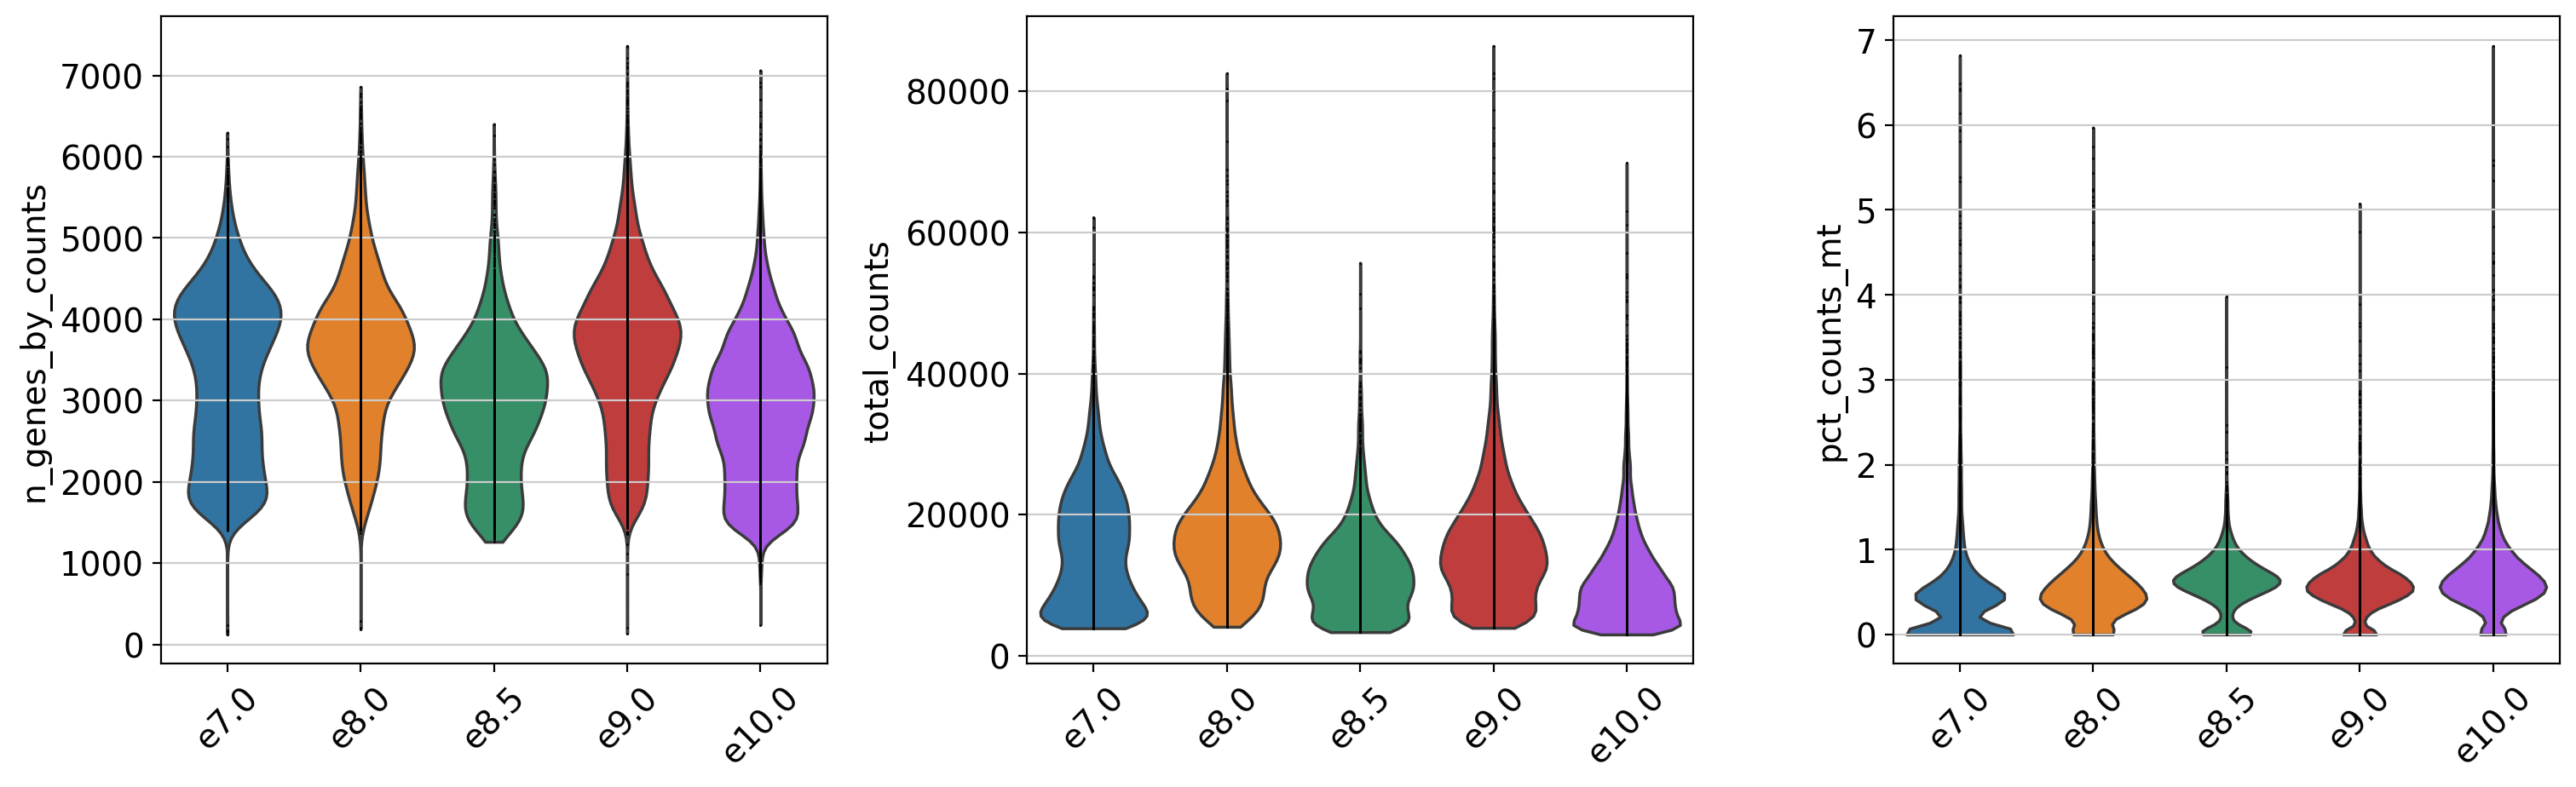

In [6]:
sc.settings.figdir = fig_qc

sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    groupby="age", rotation=45, jitter=False, multi_panel=False,
    save="_qc_by_age.png",
)

## Filtering

Cells were already called by the ordmag heuristic (>=500 UMI), so this is a light pass:
drop cells with <500 detected genes or >15% mitochondrial counts, and genes seen in <3 cells.

In [7]:
n0 = adata.shape
sc.pp.filter_cells(adata, min_genes=500)
adata = adata[adata.obs["pct_counts_mt"] < 15].copy()
sc.pp.filter_genes(adata, min_cells=3)
print(f"{n0} -> {adata.shape}")
print(adata.obs.groupby("age", observed=True).size())

filtered out 11 cells that have less than 500 genes expressed


filtered out 2448 genes that are detected in less than 3 cells


(68177, 24191) -> (68166, 21743)
age
e7.0     11195
e8.0      6813
e8.5      3241
e9.0     14781
e10.0    32136
dtype: int64


## Normalization

Counts per 10,000 then log1p; raw counts stay in `layers['counts']` for later trajectory/velocity work;
`adata.X` keeps the log-normalized values.

In [8]:
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
# no .raw / no second lognorm layer: adata.X *is* the log-normalized matrix
# (scaling happens on the HVG copy below), and each extra copy of a 216M-nnz
# matrix costs ~1.7 GB. Plots below therefore pass use_raw=False.

normalizing counts per cell


    finished (0:00:00)


## Highly variable genes

extracting highly variable genes


    finished (0:00:08)


2000 HVGs


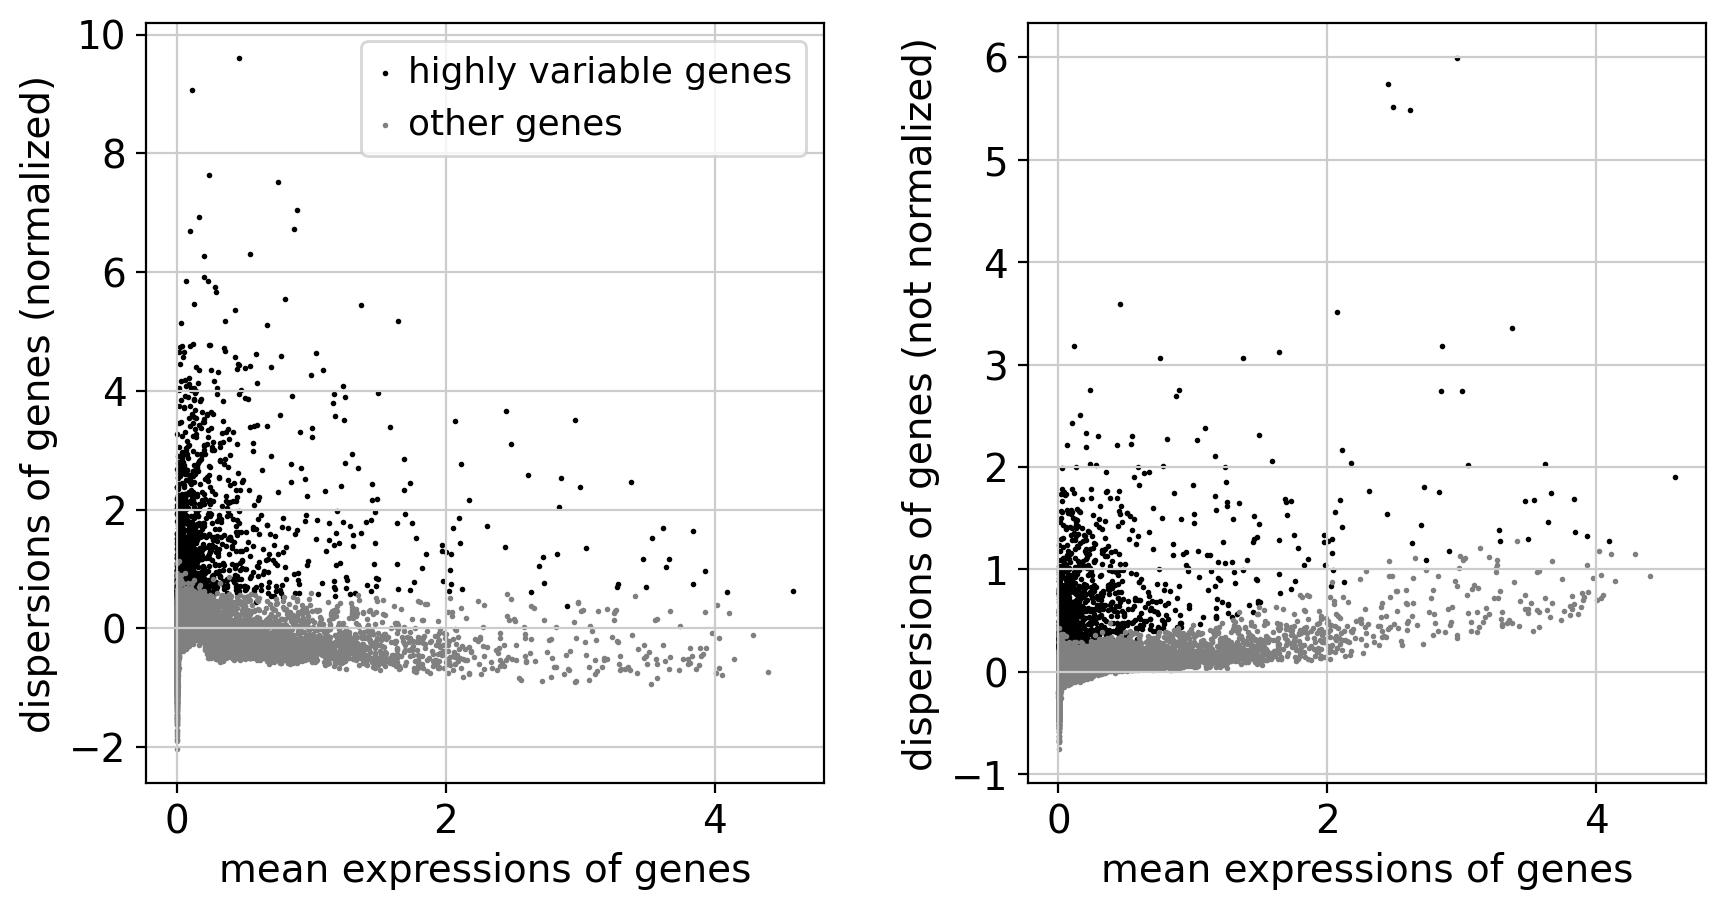

In [9]:
sc.settings.figdir = fig_pca

sc.pp.highly_variable_genes(
    adata, n_top_genes=2000, flavor="seurat", batch_key="sample"
)
print(adata.var["highly_variable"].sum(), "HVGs")
sc.pl.highly_variable_genes(adata, save="_hvg.png")

## PCA

In [ ]:
import gc

# PCA on the scaled HVG subset only; adata.X itself stays log-normalized so the
# feature plots keep reading real expression values.
adata_hvg = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, n_comps=50, svd_solver="arpack")

# carry the embedding back onto the full object
adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"]
adata.uns["pca"] = adata_hvg.uns["pca"]
adata.varm["PCs"] = np.zeros((adata.n_vars, 50), dtype=np.float32)
adata.varm["PCs"][adata.var["highly_variable"].values] = adata_hvg.varm["PCs"]
del adata_hvg
gc.collect()

print(f"X_pca: {adata.obsm['X_pca'].shape}")

In [ ]:
# sc.pl.pca_variance_ratio(log=True) plots the *natural* log of a fraction, so
# every point is negative and the magnitudes are hard to read. Plot the plain
# percentages plus the cumulative curve instead.
vr = adata.uns["pca"]["variance_ratio"]
x = np.arange(1, len(vr) + 1)
N_PCS = 30

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.plot(x, 100 * vr, "-o", color="#E32F27", lw=1.5, ms=4)
a1.set_xlabel("principal component"); a1.set_ylabel("variance explained (%)")
a1.set_title("Per-PC variance", fontsize=11)

a2.plot(x, 100 * np.cumsum(vr), "-o", color="#E32F27", lw=1.5, ms=4)
a2.set_xlabel("principal component"); a2.set_ylabel("cumulative variance explained (%)")
a2.set_title(f"Cumulative: {100*vr[:N_PCS].sum():.1f}% at {N_PCS} PCs, "
             f"{100*vr.sum():.1f}% at {len(vr)}", fontsize=11)

for a in (a1, a2):
    a.axvline(N_PCS, color="#999999", lw=1, ls="--")
    a.grid(alpha=0.25, lw=0.6)
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(fig_pca + "pca_scree.png", dpi=200, bbox_inches="tight")

print(f"PC1 {100*vr[0]:.2f}%   first {N_PCS} PCs {100*vr[:N_PCS].sum():.1f}%")

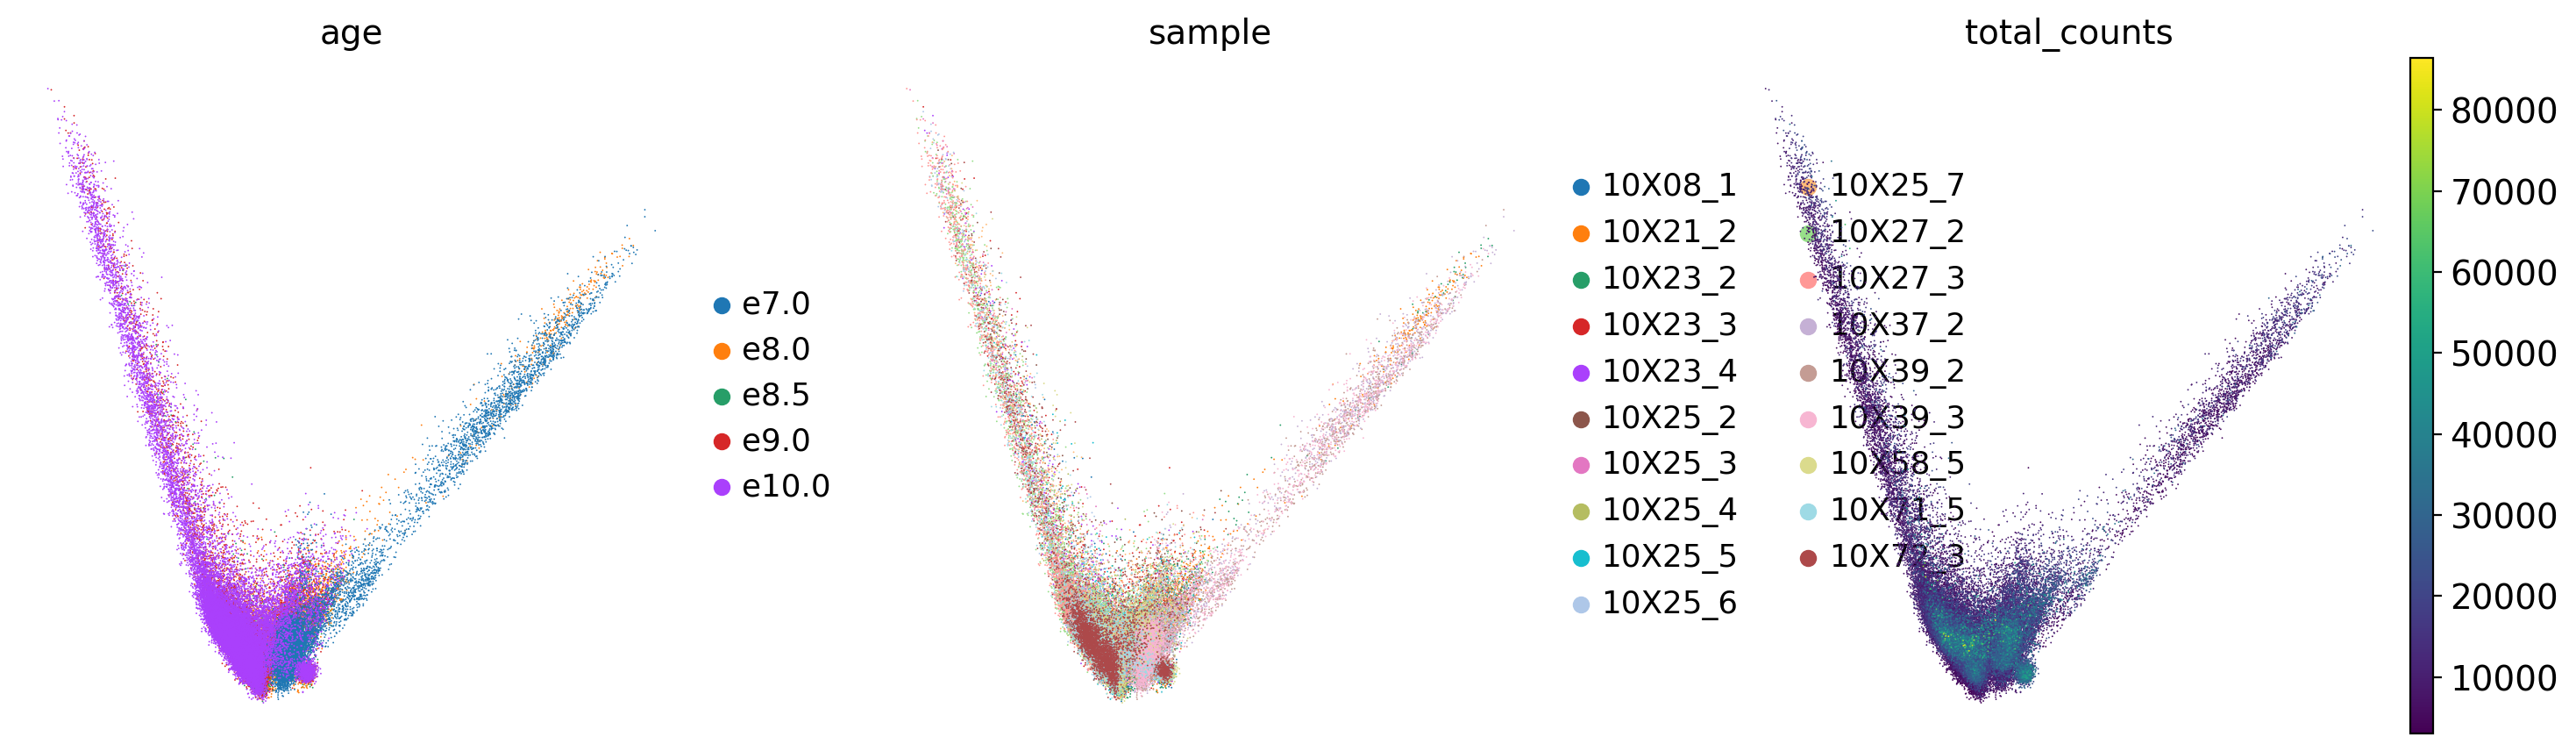

In [11]:
sc.settings.figdir = fig_pca

sc.pl.pca(adata, color=["age", "sample", "total_counts"], ncols=3, save="_age_sample.png")

## Neighbors, UMAP, Leiden

Plain PCA space, no batch correction - this is the baseline the Harmony section below
is compared against. The samples span five timepoints and several dissected regions, so
some of the structure here is real biology and some is sample-of-origin.

In [12]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata, min_dist=0.3)
sc.tl.leiden(adata, resolution=1.0, key_added="leiden", flavor="igraph", n_iterations=2)
print(adata.obs["leiden"].value_counts().sort_index())

computing neighbors


    using 'X_pca' with n_pcs = 30


/home/yubin/.conda/envs/scRNAseq_python/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished (0:00:35)


computing UMAP


    finished (0:01:10)


running Leiden clustering


    finished (0:00:03)


leiden
0     1113
1     2117
2      250
3     3598
4     2136
5     1265
6     2550
7     1026
8     1482
9     2052
10    2825
11     965
12    1937
13    1936
14    2494
15    2629
16     285
17    2781
18    2675
19     892
20    2418
21    1096
22    1234
23    2935
24     955
25    2805
26    3273
27    5691
28    1742
29    3525
30     200
31     947
32    1230
33    2731
34     376
Name: count, dtype: int64


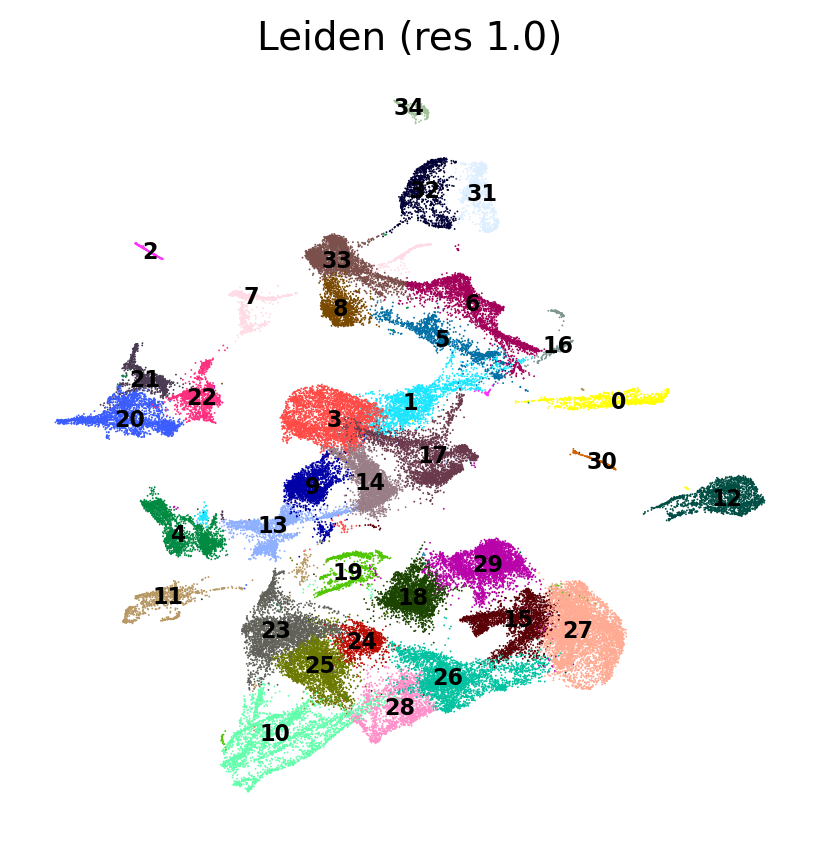

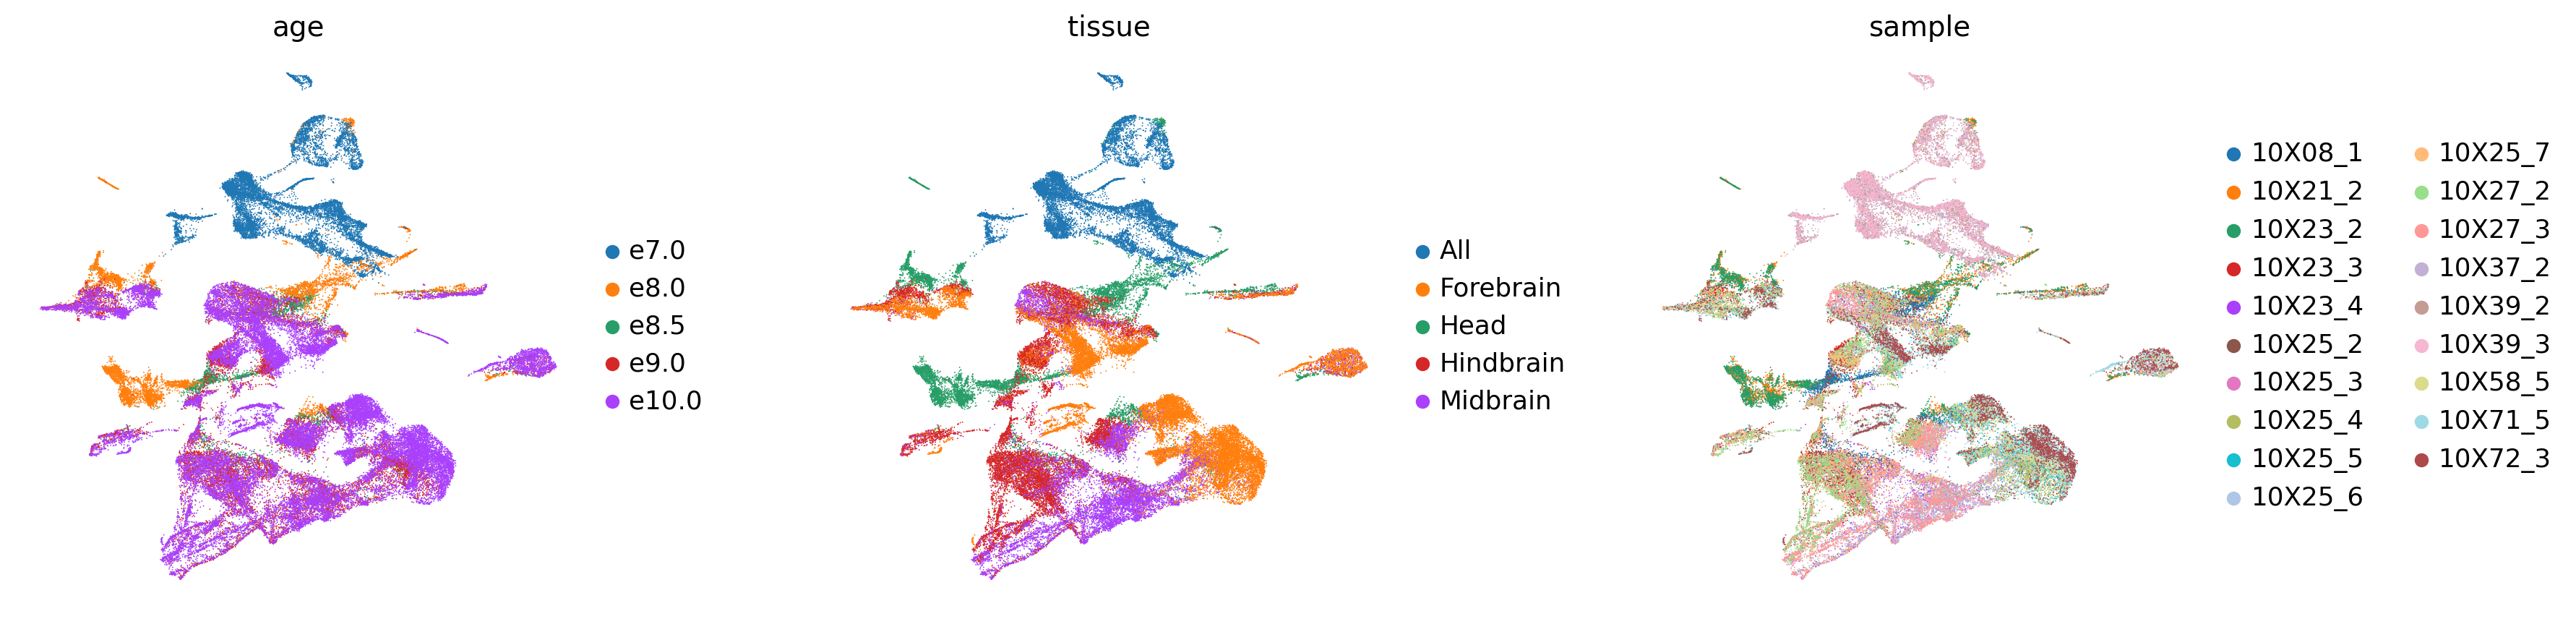

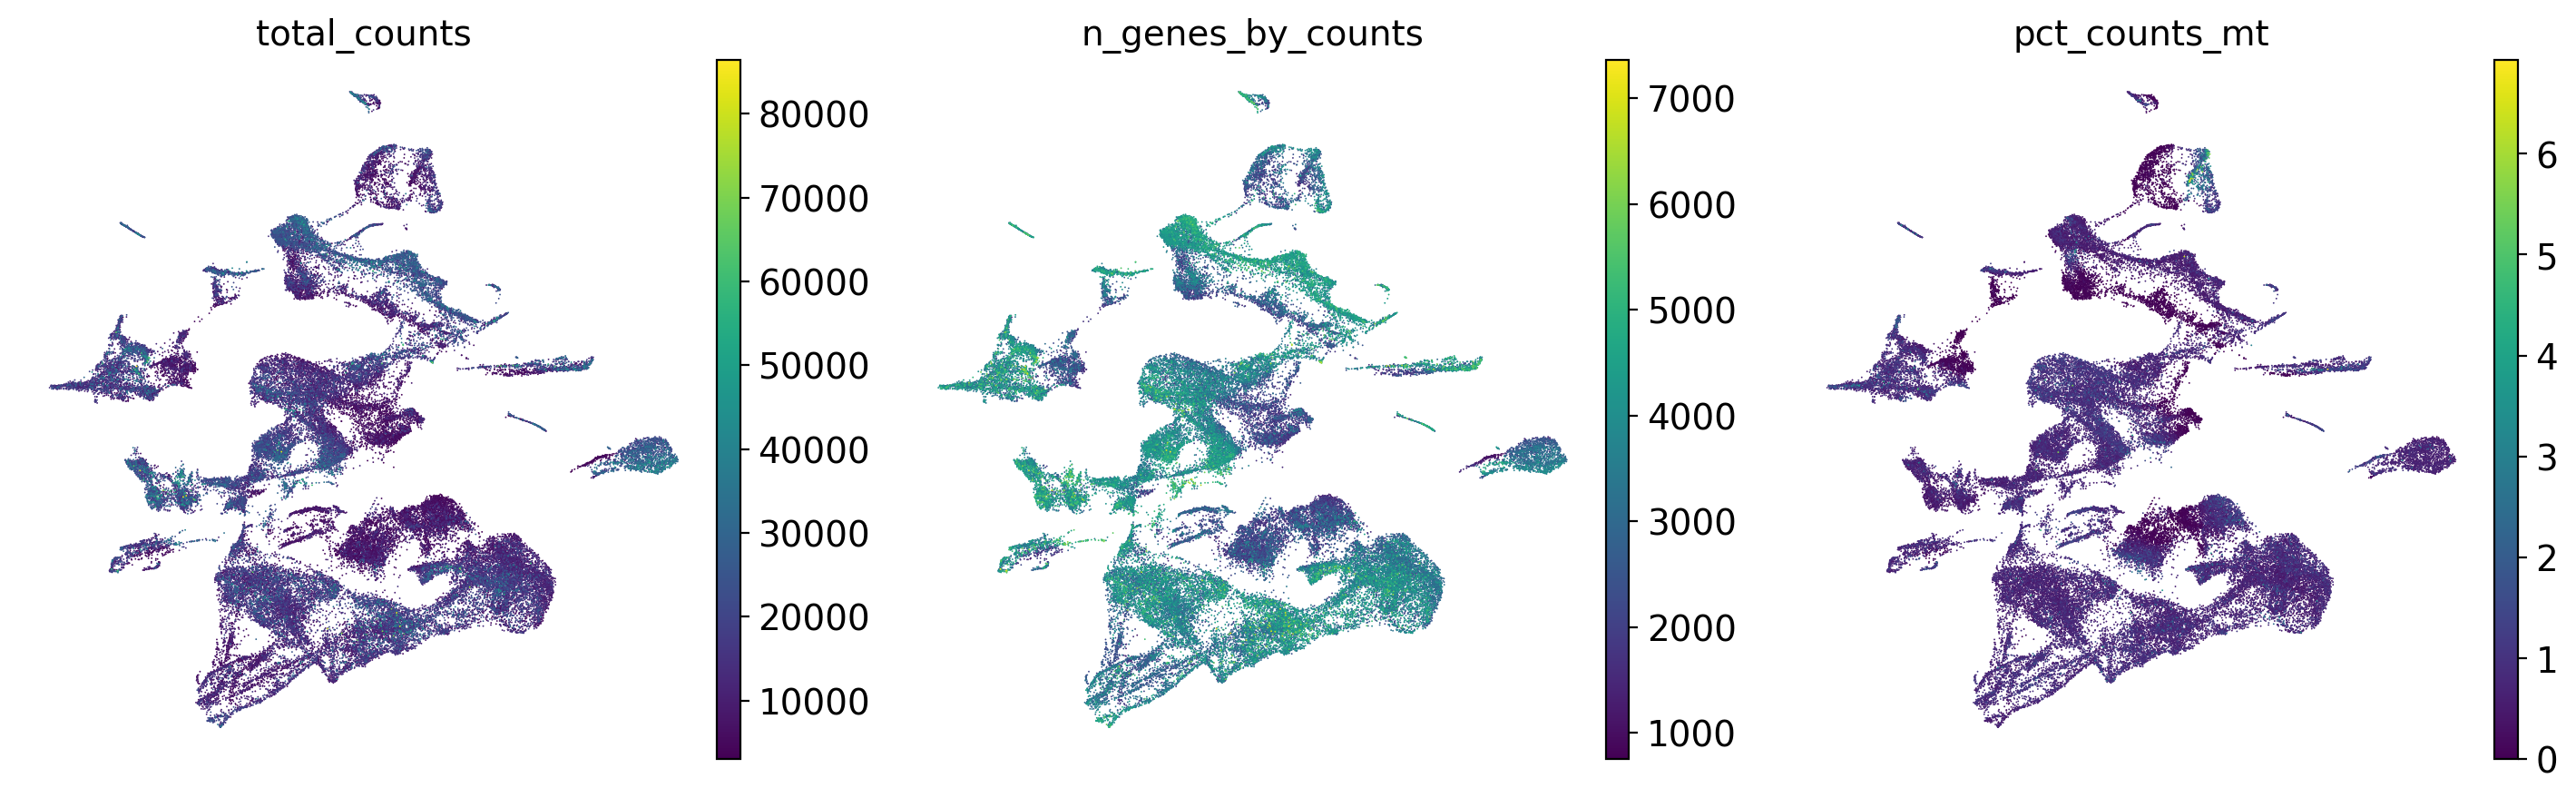

In [13]:
sc.settings.figdir = fig_umap

sc.pl.umap(adata, color="leiden", legend_loc="on data", legend_fontsize=8,
           title="Leiden (res 1.0)", save="_leiden.png")
sc.pl.umap(adata, color=["age", "tissue", "sample"], ncols=3, wspace=0.3,
           save="_age_tissue_sample.png")
sc.pl.umap(adata, color=["total_counts", "n_genes_by_counts", "pct_counts_mt"], ncols=3,
           save="_qc.png")

In [ ]:
def facet_umap(adata, key, ncols=3, bg_size=1.0, fg_size=3.0, show_all=True,
               basis="X_umap", suffix=""):
    """One UMAP panel per category - overlapping groups are unreadable in a
    single plot. Every panel shares the full embedding's limits, so a cluster
    sits at the same spot in each, with the other cells greyed out behind it."""
    cats = list(adata.obs[key].cat.categories)
    colors = adata.uns.get(f"{key}_colors", None)
    if colors is None:
        colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    xy = adata.obsm[basis]
    n = len(cats) + (1 if show_all else 0)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.0 * nrows))
    axes = np.atleast_1d(axes).ravel()
    pad = 0.03 * (xy.max(0) - xy.min(0))
    xlim = (xy[:, 0].min() - pad[0], xy[:, 0].max() + pad[0])
    ylim = (xy[:, 1].min() - pad[1], xy[:, 1].max() + pad[1])

    for i, cat in enumerate(cats):
        ax, m = axes[i], (adata.obs[key] == cat).values
        ax.scatter(xy[~m, 0], xy[~m, 1], s=bg_size, c=BG_GREY, linewidths=0,
                   rasterized=True)
        ax.scatter(xy[m, 0], xy[m, 1], s=fg_size, c=colors[i], linewidths=0,
                   rasterized=True)
        ax.set_title(f"{cat}   {m.sum():,} cells  ({100*m.mean():.0f}%)",
                     fontsize=11, color=colors[i])
    if show_all:
        ax = axes[len(cats)]
        for i, cat in enumerate(cats):
            m = (adata.obs[key] == cat).values
            ax.scatter(xy[m, 0], xy[m, 1], s=bg_size, c=colors[i], linewidths=0,
                       rasterized=True)
        ax.set_title(f"all {key}", fontsize=11)

    for ax in axes:
        ax.set_xlim(*xlim); ax.set_ylim(*ylim)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
    for ax in axes[n:]:
        ax.set_visible(False)
    fig.suptitle(f"UMAP split by {key}{suffix} (grey = all other cells)", fontsize=13)
    fig.tight_layout()
    return fig


for key in ("age", "tissue"):
    fig = facet_umap(adata, key)
    fig.savefig(fig_umap + f"umap_facet_{key}.png", dpi=200, bbox_inches="tight")

### Do the timepoints share neighbours?

e7.0 and e8.0 sit in near-isolated regions of the graph, which caps what any trajectory method can connect.

In [ ]:
def neighbour_mixing(adata, key, neighbors_key=None, verbose=True):
    """Mean share of each cell's kNN neighbours coming from each category.

    If a group sits in its own component of the graph its row is ~100% on the
    diagonal, and no pseudotime or velocity method can traverse into it.
    """
    obsp_key = "connectivities" if neighbors_key is None else f"{neighbors_key}_connectivities"
    A = (adata.obsp[obsp_key] > 0).astype(np.float32)
    cats = list(adata.obs[key].cat.categories)
    onehot = np.zeros((adata.n_obs, len(cats)), dtype=np.float32)
    onehot[np.arange(adata.n_obs), adata.obs[key].cat.codes.values] = 1
    frac = A @ onehot
    frac = frac / np.maximum(frac.sum(1, keepdims=True), 1)

    mix = pd.DataFrame(
        [frac[(adata.obs[key] == c).values].mean(0) for c in cats],
        index=cats, columns=cats,
    )
    self_share = pd.Series(
        [float((frac[(adata.obs[key] == c).values][:, i] > 0.9).mean()) for i, c in enumerate(cats)],
        index=cats, name=">90% own group",
    )
    if verbose:
        print(f"mean fraction of kNN neighbours by {key} (rows = cell's own {key})")
        print((100 * mix).round(1))
        print(f"\nshare of cells whose neighbourhood is >90% their own {key}:")
        print((100 * self_share).round(1).to_string())
    return mix, self_share


mix_age_pre, self_age_pre = neighbour_mixing(adata, "age")

## Harmony integration on `chip`

`chip` is the 10x Chromium run (the `10X25` in `10X25_2`). It is the only batch label here
that is **not** perfectly nested inside `age`: `10X23` spans e8.0+e9.0 and `10X25` spans
e9.0+e10.0, while the other seven chips are single-age.

This is why we do *not* integrate on `sample`: every library is exactly one timepoint, so
Harmony could not distinguish "library effect" from "developmental stage" and would remove
the biology the trajectory depends on. Integrating on `chip` can only pull together the
ages that genuinely share a chip, and leaves e7.0 (`10X37`, `10X39`) untouched since no
chip spans it and anything later.

Both embeddings are kept: `X_umap` stays unintegrated, `X_umap_harmony` is the corrected one.

In [ ]:
adata.obs["chip"] = (
    adata.obs["sample"].astype(str).str.split("_").str[0].astype("category")
)
print(pd.crosstab(adata.obs["chip"], adata.obs["age"]))
print("\ncells per chip:")
print(adata.obs["chip"].value_counts().sort_index().to_string())

In [ ]:
# snapshot the unintegrated embedding before sc.tl.umap overwrites X_umap
adata.obsm["X_umap_unintegrated"] = adata.obsm["X_umap"].copy()

sc.external.pp.harmony_integrate(
    adata, "chip", basis="X_pca", adjusted_basis="X_pca_harmony", max_iter_harmony=20
)

# second graph + embedding, kept alongside the unintegrated pair
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca_harmony",
                key_added="harmony")
sc.tl.umap(adata, min_dist=0.3, neighbors_key="harmony")
adata.obsm["X_umap_harmony"] = adata.obsm["X_umap"].copy()
adata.obsm["X_umap"] = adata.obsm["X_umap_unintegrated"].copy()   # restore

sc.tl.leiden(adata, resolution=1.0, key_added="leiden_harmony", flavor="igraph",
             n_iterations=2, neighbors_key="harmony")
print(f"\nleiden clusters: {adata.obs['leiden'].nunique()} unintegrated -> "
      f"{adata.obs['leiden_harmony'].nunique()} after Harmony")

### Before / after

In [ ]:
def side_by_side(adata, key, fname, ncols=2, size=1.2):
    """Same colouring on both embeddings, same axes, for a like-for-like read."""
    cats = list(adata.obs[key].cat.categories)
    colors = adata.uns.get(f"{key}_colors", plt.rcParams["axes.prop_cycle"].by_key()["color"])
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    for ax, basis, label in zip(axes, ["X_umap", "X_umap_harmony"],
                                ["unintegrated", "Harmony on chip"]):
        xy = adata.obsm[basis]
        for i, c in enumerate(cats):
            m = (adata.obs[key] == c).values
            ax.scatter(xy[m, 0], xy[m, 1], s=size, c=colors[i], linewidths=0,
                       rasterized=True, label=c)
        ax.set_title(f"{label}", fontsize=12)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
    axes[1].legend(markerscale=8, fontsize=9, frameon=False, loc="center left",
                   bbox_to_anchor=(1.01, 0.5), title=key)
    fig.suptitle(f"coloured by {key}", fontsize=13)
    fig.tight_layout()
    fig.savefig(fig_harmony + fname, dpi=200, bbox_inches="tight")
    return fig


for key in ("chip", "age", "tissue"):
    side_by_side(adata, key, f"before_after_{key}.png")

In [ ]:
for key in ("age", "chip"):
    fig = facet_umap(adata, key, basis="X_umap_harmony", suffix=" (Harmony on chip)",
                     ncols=4 if key == "chip" else 3)
    fig.savefig(fig_harmony + f"umap_facet_{key}_harmony.png", dpi=200,
                bbox_inches="tight")

### Did it mix anything?

The honest test is whether neighbourhoods became more mixed. `chip` should mix more
(that is the point); `age` should mix *only* where chips genuinely overlap in time -
if e7.0 suddenly gained neighbours from e10.0, that would be Harmony inventing a
continuum rather than removing a batch effect.

In [ ]:
print("=" * 34, "BEFORE", "=" * 34)
mix_chip_pre, self_chip_pre = neighbour_mixing(adata, "chip")
print("\n" + "=" * 34, "AFTER", "=" * 35)
mix_chip_post, self_chip_post = neighbour_mixing(adata, "chip", neighbors_key="harmony")

print("\n--- own-chip neighbour share, before vs after ---")
cmp_chip = pd.DataFrame({
    "before": 100 * pd.Series(np.diag(mix_chip_pre), index=mix_chip_pre.index),
    "after":  100 * pd.Series(np.diag(mix_chip_post), index=mix_chip_post.index),
})
cmp_chip["change"] = cmp_chip["after"] - cmp_chip["before"]
print(cmp_chip.round(1).to_string())

In [ ]:
print("=" * 34, "AGE, AFTER HARMONY", "=" * 22)
mix_age_post, self_age_post = neighbour_mixing(adata, "age", neighbors_key="harmony")

print("\n--- own-age neighbour share, before vs after ---")
cmp_age = pd.DataFrame({
    "before": 100 * pd.Series(np.diag(mix_age_pre), index=mix_age_pre.index),
    "after":  100 * pd.Series(np.diag(mix_age_post), index=mix_age_post.index),
})
cmp_age["change"] = cmp_age["after"] - cmp_age["before"]
print(cmp_age.round(1).to_string())

print("\ne7.0 -> later timepoints, neighbour share (should stay ~0):")
print(pd.DataFrame({"before": 100 * mix_age_pre.loc["e7.0"],
                    "after":  100 * mix_age_post.loc["e7.0"]}).round(2).to_string())

## Hedgehog pathway feature plots

`Gli1`, `Hhip`, `Smo` and `Shh` (reading "Hhh" as the ligand `Shh` - there is no gene
named `Hhh` in the reference). Values are log-normalized counts from `adata.X`.

In [ ]:
def feature_umap(adata, gene, ax=None, pct=99.0, bg_size=1.5, fg_size=6.0,
                 layer=None, basis="X_umap"):
    """UMAP coloured by one gene, with non-expressing cells as grey background."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.5))
    xy = adata.obsm[basis]
    v = adata[:, gene].layers[layer] if layer else adata[:, gene].X
    v = np.asarray(v.todense()).ravel() if hasattr(v, "todense") else np.ravel(v)

    on = v > 0
    vmax = np.percentile(v[on], pct) if on.any() else 1.0
    ax.scatter(xy[~on, 0], xy[~on, 1], s=bg_size, c=BG_GREY, linewidths=0,
               rasterized=True)
    o = np.argsort(v[on])                      # brightest painted last
    pts, vals = xy[on][o], v[on][o]
    sc_ = ax.scatter(pts[:, 0], pts[:, 1], s=fg_size, c=vals, cmap=EXPR_CMAP,
                     vmin=0, vmax=vmax, linewidths=0, rasterized=True)
    ax.set_title(f"{gene}   {on.sum():,} of {adata.n_obs:,} cells", fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    cb = plt.colorbar(sc_, ax=ax, fraction=0.035, pad=0.01)
    cb.ax.tick_params(labelsize=8, length=2)
    cb.outline.set_visible(False)
    return ax


genes = ["Gli1", "Hhip", "Smo", "Shh"]
print({g: g in adata.var_names for g in genes})
for g in genes:
    v = np.asarray(adata[:, g].X.todense()).ravel()
    print(f"  {g:5s} expressing {int((v > 0).sum()):6d}  max {v.max():.2f}  "
          f"p99 of expressing {np.percentile(v[v > 0], 99):.2f}")

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, g in zip(axes.ravel(), genes):
    feature_umap(adata, g, ax=ax)
fig.suptitle("Hedgehog pathway, log1p CP10K (grey = no detected transcript)",
             fontsize=12)
fig.tight_layout()
fig.savefig(fig_genes + "umap_hedgehog_genes.png", dpi=200, bbox_inches="tight")

In [ ]:
# one larger panel per gene
for g in genes:
    ax = feature_umap(adata, g, fg_size=9.0)
    ax.figure.tight_layout()
    ax.figure.savefig(fig_genes + f"umap_gene_{g}.png", dpi=200,
                      bbox_inches="tight")
    plt.close(ax.figure)

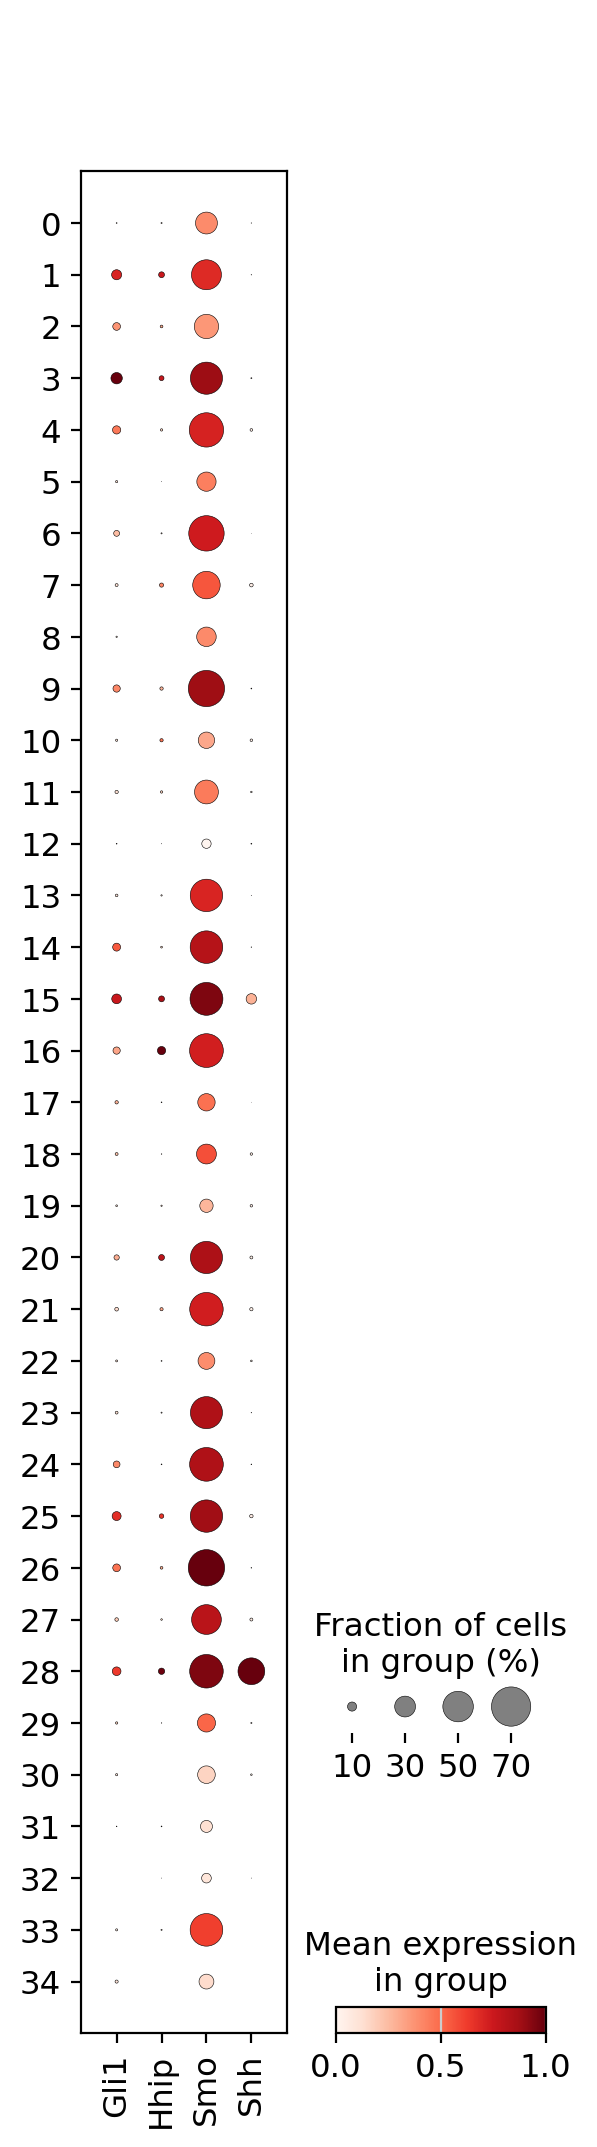

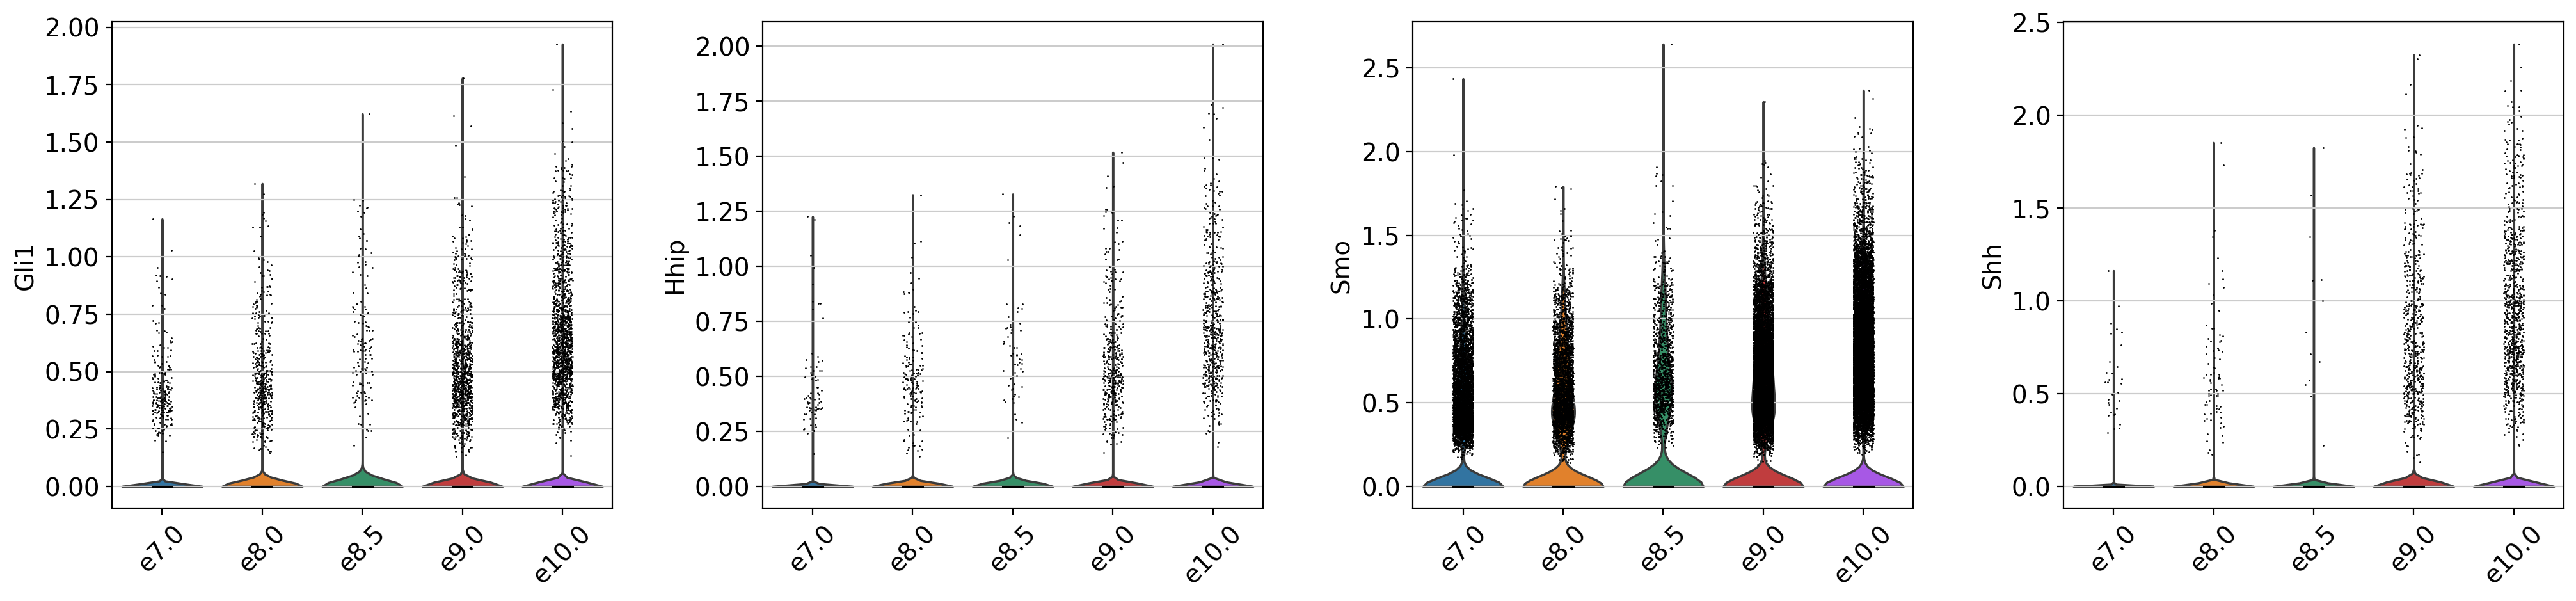

In [16]:
sc.settings.figdir = fig_genes

sc.pl.dotplot(adata, genes, groupby="leiden", standard_scale="var", use_raw=False,
              save="_hedgehog_by_leiden.png")
sc.pl.violin(adata, genes, groupby="age", rotation=45, use_raw=False,
             save="_hedgehog_by_age.png")

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, g in zip(axes.ravel(), genes):
    feature_umap(adata, g, ax=ax, basis="X_umap_harmony")
fig.suptitle("Hedgehog pathway on the Harmony embedding, log1p CP10K", fontsize=12)
fig.tight_layout()
fig.savefig(fig_harmony + "umap_hedgehog_genes_harmony.png", dpi=200,
            bbox_inches="tight")

## Save

In [17]:
import resource
print(f"peak RSS: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.1f} GB")

out = base + "data/devbrain_E7-E10_processed.h5ad"
adata.write_h5ad(out, compression="gzip")
print(f"wrote {out}: {adata.n_obs} x {adata.n_vars}")
adata

peak RSS: 9.1 GB


wrote /project/imoskowitz/yubin/Trajectory_inference/data/devbrain_E7-E10_processed.h5ad: 68166 x 21743


AnnData object with n_obs × n_vars = 68166 × 21743
    obs: 'barcode', 'sample', 'run', 'age', 'tissue', 'total_counts', 'n_genes', 'is_cell', 'age_num', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'leiden'
    var: 'gene_ids', 'gene_symbol', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'source', 'age_colors', 'log1p', 'hvg', 'pca', 'sample_colors', 'neighbors', 'umap', 'leiden', 'leiden_colors', 'tissue_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'